# Efficient Edge AI for Forest Fire Detection

## 1.Project Overview

This project investigates the use of deep learning and Edge AI techniques for real-time forest fire detection using image classification. A publicly available Forest Fire Dataset obtained from Kaggle is used to train and evaluate multiple image classification models, including a custom CNN baseline, MobileNetV2, and EfficientNet-B0.

The study focuses on comparing edge-based and cloud-based inference scenarios in terms of classification performance, latency, bandwidth usage, model size, and computational efficiency. Since early wildfire detection often requires rapid decision-making in remote environments with limited connectivity, deploying artificial intelligence directly on edge devices may provide significant practical advantages.

The proposed system aims to support early fire detection in resource-constrained environments where continuous cloud communication may not always be reliable or efficient. By performing inference locally on edge devices, the system seeks to reduce response time, minimise unnecessary data transmission, and improve overall deployment efficiency.

The project includes:

* Dataset preparation and preprocessing
* Exploratory Data Analysis (EDA)
* Development of deep learning classification models
* Transfer learning using pretrained architectures
* Edge-oriented model optimisation techniques
* Edge versus cloud performance comparison
* Latency, bandwidth, and efficiency analysis
* Ethical and sustainability considerations

---

### Project Objectives

The objectives of this project are:

* To develop a deep learning model capable of classifying fire and non-fire images
* To compare the performance of different deep learning architectures
* To optimise selected models for deployment in resource-constrained edge environments
* To evaluate model performance using appropriate classification metrics
* To compare edge and cloud inference scenarios in terms of latency and bandwidth requirements
* To analyse the suitability of Efficient AI approaches for real-world wildfire monitoring applications

---

### Technologies and Tools

This project is implemented using:

* Python
* Google Colab
* PyTorch
* NumPy
* Pandas
* Matplotlib
* Seaborn
* Kaggle API

---

### Workflow

The notebook follows the workflow below:

1. Project Setup
2. Dataset Download and Inspection
3. Exploratory Data Analysis (EDA)
4. Data Preprocessing
5. Baseline CNN Development
6. Transfer Learning Models
7. Model Evaluation
8. Edge AI Optimisation
9. Edge vs Cloud Comparison
10. Bandwidth and Efficiency Analysis
11. Final Results and Discussion


In [ ]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [ ]:
warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

print("Random seed set successfully.")

Random seed set successfully.


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {device}")

if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
else:
    print("CUDA is not available. Running on CPU.")

Using device: cuda
GPU Name: Tesla T4


In [ ]:
PROJECT_DIR = "/content/forest_fire_project"

DATASET_DIR = os.path.join(PROJECT_DIR, "dataset")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(DATASET_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Project directories created successfully.")
print(f"Project directory: {PROJECT_DIR}")

Project directories created successfully.
Project directory: /content/forest_fire_project


# 2. Dataset Download and Preparation

The Forest Fire Dataset is downloaded from Kaggle and extracted into the project workspace. The dataset contains images representing fire and non-fire scenarios and serves as the foundation for all experiments conducted in this study.

After extraction, the dataset structure is inspected to verify that all files have been downloaded correctly and are organised as expected. The images are then prepared for subsequent preprocessing, training, and evaluation stages.

The dataset is used throughout the project to investigate the performance of deep learning models in both edge-based and cloud-based inference environments.

In [ ]:
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")


In [ ]:
#!/bin/bash

!mkdir -p /content/forest_fire_project/dataset

!kaggle datasets download \
-d alik05/forest-fire-dataset \
-p /content/forest_fire_project/dataset

!unzip -o "/content/forest_fire_project/dataset/*.zip" \
-d /content/forest_fire_project/dataset

Dataset URL: https://www.kaggle.com/datasets/alik05/forest-fire-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 142M/142M [00:01<00:00, 147MB/s]

Archive:  /content/forest_fire_project/dataset/forest-fire-dataset.zip
  inflating: /content/forest_fire_project/dataset/Forest Fire Dataset/Testing/fire_0002.jpg  
  inflating: /content/forest_fire_project/dataset/Forest Fire Dataset/Testing/fire_0015.jpg  
  inflating: /content/forest_fire_project/dataset/Forest Fire Dataset/Testing/fire_0027.jpg  
  inflating: /content/forest_fire_project/dataset/Forest Fire Dataset/Testing/fire_0038.jpg  
  inflating: /content/forest_fire_project/dataset/Forest Fire Dataset/Testing/fire_0040.jpg  
  inflating: /content/forest_fire_project/dataset/Forest Fire Dataset/Testing/fire_0048.jpg  
  inflating: /content/forest_fire_project/dataset/Forest Fire Dataset/Testing/fire_0063.jpg  
  inflating: /content/forest_fire_project/dataset/Forest Fire Dataset/Testing/fire_0072.jpg  
  inflating:

# 3. Dataset Inspection and Exploratory Data Analysis (EDA)

Before model development, an Exploratory Data Analysis (EDA) is conducted to better understand the characteristics and quality of the Forest Fire Dataset. This stage helps identify potential issues that may affect model performance and provides insights that support later preprocessing decisions.

The analysis includes an examination of class distributions, sample image visualisation, image resolution statistics, and dataset quality checks. In particular, the dataset is inspected for class imbalance, variations in image dimensions, and the presence of corrupted or unreadable files.

The findings from this analysis provide a clearer understanding of the dataset and help justify the preprocessing and modelling choices used throughout the project.


In [ ]:
train_fire_dir = os.path.join(DATASET_DIR, "Forest Fire Dataset", "Training", "fire")
train_nofire_dir = os.path.join(DATASET_DIR, "Forest Fire Dataset", "Training", "nofire")
test_dir = os.path.join(DATASET_DIR, "Forest Fire Dataset", "Testing")

fire_images = [
    img for img in os.listdir(train_fire_dir)
    if img.lower().endswith((".jpg", ".jpeg", ".png"))
]

nofire_images = [
    img for img in os.listdir(train_nofire_dir)
    if img.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Dataset paths loaded successfully.")
print(f"Fire directory: {train_fire_dir}")
print(f"Non-fire directory: {train_nofire_dir}")
print(f"Testing directory: {test_dir}")

Dataset paths loaded successfully.
Fire directory: /content/forest_fire_project/dataset/Forest Fire Dataset/Training/fire
Non-fire directory: /content/forest_fire_project/dataset/Forest Fire Dataset/Training/nofire
Testing directory: /content/forest_fire_project/dataset/Forest Fire Dataset/Testing


Training Dataset Class Distribution
      Class  Number of Images
0      Fire               760
1  Non-Fire               760

Total training images: 1520


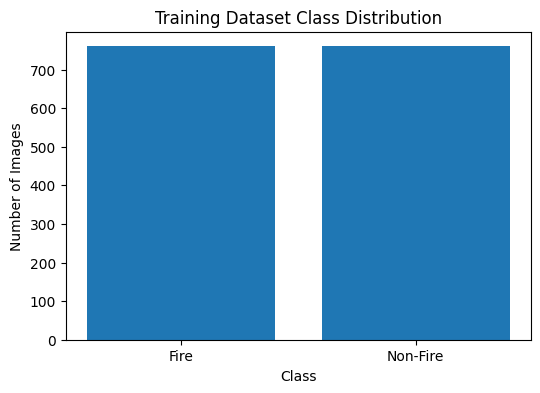

In [ ]:
fire_count = len(fire_images)
nofire_count = len(nofire_images)
total_train_images = fire_count + nofire_count

class_distribution = pd.DataFrame({
    "Class": ["Fire", "Non-Fire"],
    "Number of Images": [fire_count, nofire_count]
})

print("Training Dataset Class Distribution")
print(class_distribution)
print(f"\nTotal training images: {total_train_images}")

plt.figure(figsize=(6, 4))
plt.bar(class_distribution["Class"], class_distribution["Number of Images"])
plt.title("Training Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

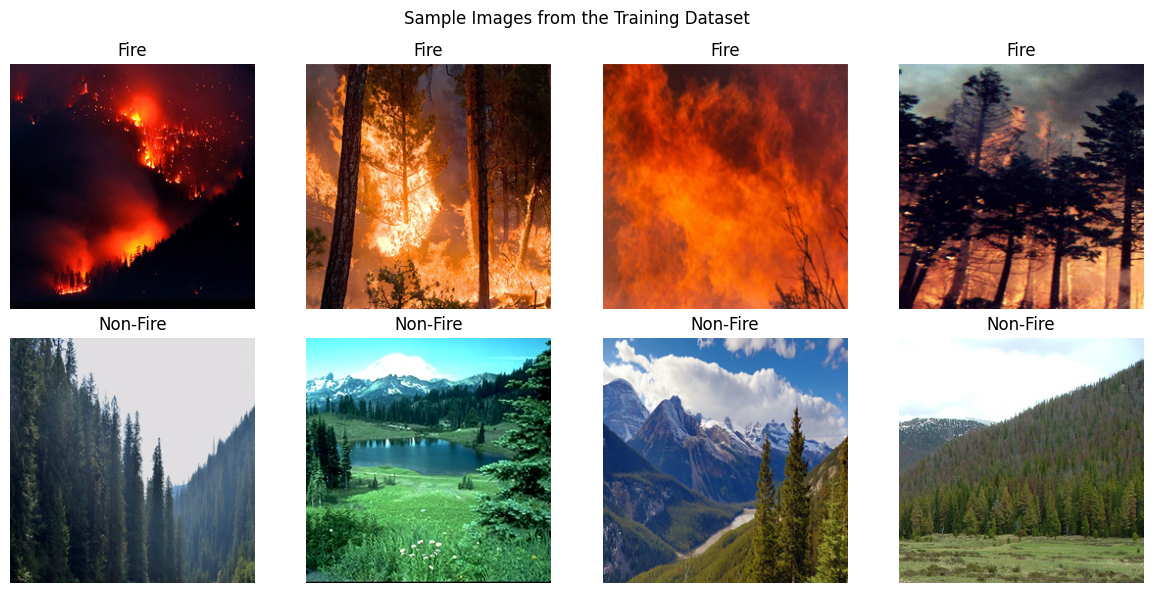

In [ ]:
sample_fire_images = random.sample(fire_images, min(4, len(fire_images)))
sample_nofire_images = random.sample(nofire_images, min(4, len(nofire_images)))

plt.figure(figsize=(12, 6))

for i, img_name in enumerate(sample_fire_images):
    img_path = os.path.join(train_fire_dir, img_name)
    img = Image.open(img_path).convert("RGB")

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title("Fire")
    plt.axis("off")

for i, img_name in enumerate(sample_nofire_images):
    img_path = os.path.join(train_nofire_dir, img_name)
    img = Image.open(img_path).convert("RGB")

    plt.subplot(2, 4, i + 5)
    plt.imshow(img)
    plt.title("Non-Fire")
    plt.axis("off")

plt.suptitle("Sample Images from the Training Dataset")
plt.tight_layout()
plt.show()

Image Size Summary
    Metric   Width  Height
0  Minimum  250.00  250.00
1  Maximum  256.00  256.00
2  Average  250.22  250.22


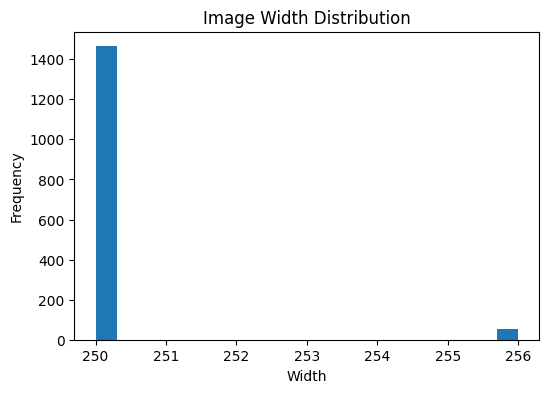

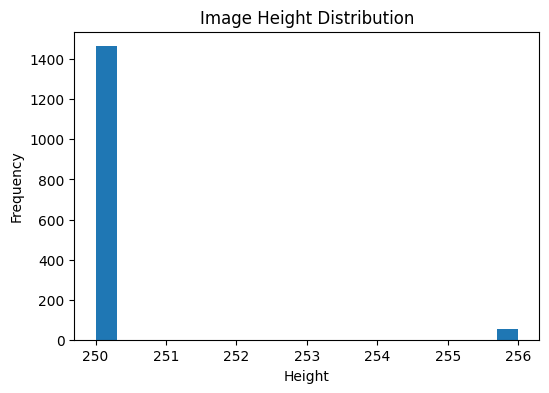

In [ ]:
all_train_image_paths = [
    os.path.join(train_fire_dir, img_name) for img_name in fire_images
] + [
    os.path.join(train_nofire_dir, img_name) for img_name in nofire_images
]

image_widths = []
image_heights = []

for img_path in all_train_image_paths:
    with Image.open(img_path) as img:
        width, height = img.size
        image_widths.append(width)
        image_heights.append(height)

image_size_summary = pd.DataFrame({
    "Metric": ["Minimum", "Maximum", "Average"],
    "Width": [
        min(image_widths),
        max(image_widths),
        round(np.mean(image_widths), 2)
    ],
    "Height": [
        min(image_heights),
        max(image_heights),
        round(np.mean(image_heights), 2)
    ]
})

print("Image Size Summary")
print(image_size_summary)

plt.figure(figsize=(6, 4))
plt.hist(image_widths, bins=20)
plt.title("Image Width Distribution")
plt.xlabel("Width")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(6, 4))
plt.hist(image_heights, bins=20)
plt.title("Image Height Distribution")
plt.xlabel("Height")
plt.ylabel("Frequency")
plt.show()

In [ ]:
corrupted_images = []

for img_path in all_train_image_paths:
    try:
        with Image.open(img_path) as img:
            img.verify()
    except Exception:
        corrupted_images.append(img_path)

print("Dataset Quality Check")
print(f"Number of corrupted images: {len(corrupted_images)}")

if corrupted_images:
    print("\nCorrupted image examples:")
    for img_path in corrupted_images[:10]:
        print(img_path)
else:
    print("No corrupted images found.")

Dataset Quality Check
Number of corrupted images: 0
No corrupted images found.


# 4. Data Preprocessing

This section prepares the image dataset for deep learning model training by applying a series of preprocessing and transformation steps. These procedures ensure that the input data is consistent, suitable for model learning, and compatible with the selected neural network architectures.

The preprocessing pipeline includes image resizing, data augmentation, normalisation, train-validation splitting, and DataLoader creation. Images are resized to a fixed input size to maintain consistency across the dataset, while normalisation is applied to standardise pixel values and support stable model training.

To improve generalisation and reduce the risk of overfitting, data augmentation techniques are applied only to the training dataset. Validation and test datasets use consistent transformations to ensure a fair and unbiased evaluation of model performance.

The final output of this stage is a set of efficiently organised PyTorch DataLoaders that are used throughout the training and evaluation process.


In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.2

print(f"Image size: {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Validation split: {VALIDATION_SPLIT}")

Image size: 224x224
Batch size: 32
Validation split: 0.2


In [ ]:
train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations defined successfully.")

Image transformations defined successfully.


In [ ]:
training_root = os.path.join(DATASET_DIR, "Forest Fire Dataset", "Training")

full_train_dataset = datasets.ImageFolder(
    root=training_root,
    transform=train_transforms
)

print("Full training dataset created successfully.")
print(f"Classes: {full_train_dataset.classes}")
print(f"Class-to-index mapping: {full_train_dataset.class_to_idx}")
print(f"Total images: {len(full_train_dataset)}")

Full training dataset created successfully.
Classes: ['fire', 'nofire']
Class-to-index mapping: {'fire': 0, 'nofire': 1}
Total images: 1520


In [ ]:
val_size = int(len(full_train_dataset) * VALIDATION_SPLIT)
train_size = len(full_train_dataset) - val_size

train_dataset, val_dataset = torch.utils.data.random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

val_dataset.dataset.transform = eval_transforms

print("Train-validation split completed.")
print(f"Training images: {train_size}")
print(f"Validation images: {val_size}")

Train-validation split completed.
Training images: 1216
Validation images: 304


In [ ]:
test_image_paths = [
    os.path.join(test_dir, img_name)
    for img_name in os.listdir(test_dir)
    if img_name.lower().endswith((".jpg", ".jpeg", ".png"))
]

test_labels = [
    1 if os.path.basename(path).startswith("fire") else 0
    for path in test_image_paths
]

print("Test dataset prepared successfully.")
print(f"Total test images: {len(test_image_paths)}")
print(f"Fire test images: {sum(test_labels)}")
print(f"Non-fire test images: {len(test_labels) - sum(test_labels)}")

Test dataset prepared successfully.
Total test images: 380
Fire test images: 190
Non-fire test images: 190


In [ ]:
from torch.utils.data import Dataset

class ForestFireTestDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]
        label = self.labels[index]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
test_dataset = ForestFireTestDataset(
    image_paths=test_image_paths,
    labels=test_labels,
    transform=eval_transforms
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders created successfully.")
print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of test batches: {len(test_loader)}")

DataLoaders created successfully.
Number of training batches: 38
Number of validation batches: 10
Number of test batches: 12


In [ ]:
images, labels = next(iter(train_loader))

print("One training batch loaded successfully.")
print(f"Image batch shape: {images.shape}")
print(f"Label batch shape: {labels.shape}")

One training batch loaded successfully.
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


# 5. Baseline CNN Model

In this section, a simple Convolutional Neural Network (CNN) is developed as the first baseline model for the forest fire classification task.

The objective of this model is not to achieve the highest possible accuracy, but to establish an initial performance benchmark against which more advanced approaches can be evaluated. Building a baseline model provides a clear reference for understanding the benefits of transfer learning and model optimisation techniques introduced later in the project.

The model is trained and evaluated using the prepared dataset, and its performance serves as a foundation for comparison with more efficient architectures such as MobileNetV2 and EfficientNet-B0.


In [ ]:
import torch.nn as nn
import torch.optim as optim

class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 28 * 28, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


baseline_model = BaselineCNN().to(device)

print(baseline_model)

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=50176, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(baseline_model.parameters(), lr=0.001)

num_epochs = 10

In [ ]:
def train_baseline_model(model, train_loader, val_loader, criterion, optimizer, num_epochs):
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_acc = correct_train / total_train

        model.eval()
        val_running_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item()

                _, predicted = torch.max(outputs, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        val_loss = val_running_loss / len(val_loader)
        val_acc = correct_val / total_val

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch [{epoch+1}/{num_epochs}]")
        print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f}")
        print("-" * 50)

    return history


baseline_history = train_baseline_model(
    baseline_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    num_epochs
)

Epoch [1/10]
Train Loss: 0.3660 | Train Accuracy: 0.8413
Val Loss: 0.1497 | Val Accuracy: 0.9441
--------------------------------------------------
Epoch [2/10]
Train Loss: 0.1504 | Train Accuracy: 0.9581
Val Loss: 0.1518 | Val Accuracy: 0.9441
--------------------------------------------------
Epoch [3/10]
Train Loss: 0.1196 | Train Accuracy: 0.9655
Val Loss: 0.1399 | Val Accuracy: 0.9474
--------------------------------------------------
Epoch [4/10]
Train Loss: 0.0931 | Train Accuracy: 0.9679
Val Loss: 0.1187 | Val Accuracy: 0.9539
--------------------------------------------------
Epoch [5/10]
Train Loss: 0.0876 | Train Accuracy: 0.9753
Val Loss: 0.1140 | Val Accuracy: 0.9572
--------------------------------------------------
Epoch [6/10]
Train Loss: 0.0998 | Train Accuracy: 0.9638
Val Loss: 0.1081 | Val Accuracy: 0.9572
--------------------------------------------------
Epoch [7/10]
Train Loss: 0.0728 | Train Accuracy: 0.9786
Val Loss: 0.1118 | Val Accuracy: 0.9638
---------------

In [ ]:
baseline_final_train_acc = baseline_history["train_acc"][-1]
baseline_final_val_acc = baseline_history["val_acc"][-1]

print("Baseline CNN Final Results")
print(f"Final Training Accuracy: {baseline_final_train_acc:.4f}")
print(f"Final Validation Accuracy: {baseline_final_val_acc:.4f}")

Baseline CNN Final Results
Final Training Accuracy: 0.9901
Final Validation Accuracy: 0.9605


# 6. Transfer Learning Models

In this section, transfer learning is applied using pretrained convolutional neural network architectures. Transfer learning enables models that have previously learned general visual features from large-scale datasets to be adapted to the forest fire classification task.

MobileNetV2 and EfficientNet-B0 are selected because they provide a strong balance between classification performance and computational efficiency. Their lightweight architectures make them particularly suitable for deployment in resource-constrained edge environments.

For each model, the original classification layer is replaced with a new binary classification head designed for fire and non-fire detection. The models are then fine-tuned using the Forest Fire Dataset and evaluated to determine their suitability for real-time edge-based applications.

These architectures were selected not only for their predictive capability but also for their potential to support efficient deployment on edge devices.


In [ ]:
from torchvision import models

def train_transfer_model(model, train_loader, val_loader, criterion, optimizer, num_epochs, model_name):
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    for epoch in range(num_epochs):

        model.train()

        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_acc = correct_train / total_train

        model.eval()

        val_running_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item()

                _, predicted = torch.max(outputs, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        val_loss = val_running_loss / len(val_loader)
        val_acc = correct_val / total_val

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"{model_name} - Epoch [{epoch+1}/{num_epochs}]")
        print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
        print(f"Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_acc:.4f}")
        print("-" * 60)

    return history

In [ ]:
mobilenet_model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

mobilenet_model.classifier[1] = nn.Linear(
    mobilenet_model.classifier[1].in_features,
    2
)

mobilenet_model = mobilenet_model.to(device)

criterion = nn.CrossEntropyLoss()

mobilenet_optimizer = optim.Adam(
    mobilenet_model.parameters(),
    lr=0.0001
)

transfer_num_epochs = 10

print(mobilenet_model)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ| 13.6M/13.6M [00:00<00:00, 147MB/s]

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

In [ ]:
mobilenet_history = train_transfer_model(
    mobilenet_model,
    train_loader,
    val_loader,
    criterion,
    mobilenet_optimizer,
    transfer_num_epochs,
    "MobileNetV2"
)

MobileNetV2 - Epoch [1/10]
Train Loss: 0.3882 | Train Accuracy: 0.9120
Validation Loss: 0.1333 | Validation Accuracy: 0.9868
------------------------------------------------------------
MobileNetV2 - Epoch [2/10]
Train Loss: 0.0891 | Train Accuracy: 0.9893
Validation Loss: 0.0540 | Validation Accuracy: 0.9868
------------------------------------------------------------
MobileNetV2 - Epoch [3/10]
Train Loss: 0.0392 | Train Accuracy: 0.9934
Validation Loss: 0.0370 | Validation Accuracy: 0.9934
------------------------------------------------------------
MobileNetV2 - Epoch [4/10]
Train Loss: 0.0408 | Train Accuracy: 0.9918
Validation Loss: 0.0310 | Validation Accuracy: 0.9934
------------------------------------------------------------
MobileNetV2 - Epoch [5/10]
Train Loss: 0.0221 | Train Accuracy: 0.9984
Validation Loss: 0.0317 | Validation Accuracy: 0.9934
------------------------------------------------------------
MobileNetV2 - Epoch [6/10]
Train Loss: 0.0096 | Train Accuracy: 0.9992

In [ ]:
efficientnet_model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

efficientnet_model.classifier[1] = nn.Linear(
    efficientnet_model.classifier[1].in_features,
    2
)

efficientnet_model = efficientnet_model.to(device)

efficientnet_optimizer = optim.Adam(
    efficientnet_model.parameters(),
    lr=0.0001
)

print(efficientnet_model)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ| 20.5M/20.5M [00:00<00:00, 107MB/s] 

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [ ]:
efficientnet_history = train_transfer_model(
    efficientnet_model,
    train_loader,
    val_loader,
    criterion,
    efficientnet_optimizer,
    transfer_num_epochs,
    "EfficientNet-B0"
)

EfficientNet-B0 - Epoch [1/10]
Train Loss: 0.3533 | Train Accuracy: 0.9145
Validation Loss: 0.0808 | Validation Accuracy: 0.9967
------------------------------------------------------------
EfficientNet-B0 - Epoch [2/10]
Train Loss: 0.0740 | Train Accuracy: 0.9877
Validation Loss: 0.0327 | Validation Accuracy: 0.9967
------------------------------------------------------------
EfficientNet-B0 - Epoch [3/10]
Train Loss: 0.0370 | Train Accuracy: 0.9942
Validation Loss: 0.0232 | Validation Accuracy: 0.9967
------------------------------------------------------------
EfficientNet-B0 - Epoch [4/10]
Train Loss: 0.0192 | Train Accuracy: 0.9984
Validation Loss: 0.0178 | Validation Accuracy: 0.9967
------------------------------------------------------------
EfficientNet-B0 - Epoch [5/10]
Train Loss: 0.0091 | Train Accuracy: 1.0000
Validation Loss: 0.0147 | Validation Accuracy: 0.9967
------------------------------------------------------------
EfficientNet-B0 - Epoch [6/10]
Train Loss: 0.0114 

In [ ]:
mobilenet_final_train_acc = mobilenet_history["train_acc"][-1]
mobilenet_final_val_acc = mobilenet_history["val_acc"][-1]

efficientnet_final_train_acc = efficientnet_history["train_acc"][-1]
efficientnet_final_val_acc = efficientnet_history["val_acc"][-1]

print("Transfer Learning Final Results")
print("-" * 40)
print(f"MobileNetV2 Training Accuracy: {mobilenet_final_train_acc:.4f}")
print(f"MobileNetV2 Validation Accuracy: {mobilenet_final_val_acc:.4f}")
print("-" * 40)
print(f"EfficientNet-B0 Training Accuracy: {efficientnet_final_train_acc:.4f}")
print(f"EfficientNet-B0 Validation Accuracy: {efficientnet_final_val_acc:.4f}")

Transfer Learning Final Results
----------------------------------------
MobileNetV2 Training Accuracy: 1.0000
MobileNetV2 Validation Accuracy: 0.9934
----------------------------------------
EfficientNet-B0 Training Accuracy: 1.0000
EfficientNet-B0 Validation Accuracy: 0.9967


The transfer learning models substantially outperformed the baseline CNN model, highlighting the benefits of leveraging pretrained feature representations for forest fire image classification.

MobileNetV2 achieved a validation accuracy of 99.34%, while EfficientNet-B0 delivered the best overall performance with a validation accuracy of 99.67%. These results indicate that pretrained models are highly effective at learning discriminative visual features relevant to fire and non-fire detection.

In addition to their strong predictive performance, both architectures are designed with computational efficiency in mind, making them suitable candidates for deployment in resource-constrained edge environments.

Based on these findings, the next stage of the project investigates deployment-related characteristics, including model size, inference latency, and the impact of model optimisation through quantisation.


# 7. Training and Evaluation

This section evaluates the performance of the trained models using a range of classification metrics. A comprehensive evaluation is essential for assessing not only overall accuracy but also the model's ability to correctly distinguish between fire and non-fire images.

Training history, accuracy and loss curves, confusion matrices, classification reports, and F1 scores are analysed to gain deeper insights into model behaviour and classification performance. These metrics help identify strengths and weaknesses in the models and provide a more complete understanding of their predictive capabilities.

The evaluation results are used to compare the baseline and transfer learning models, identify the best-performing architecture, and assess its suitability for deployment in real-world forest fire detection applications.


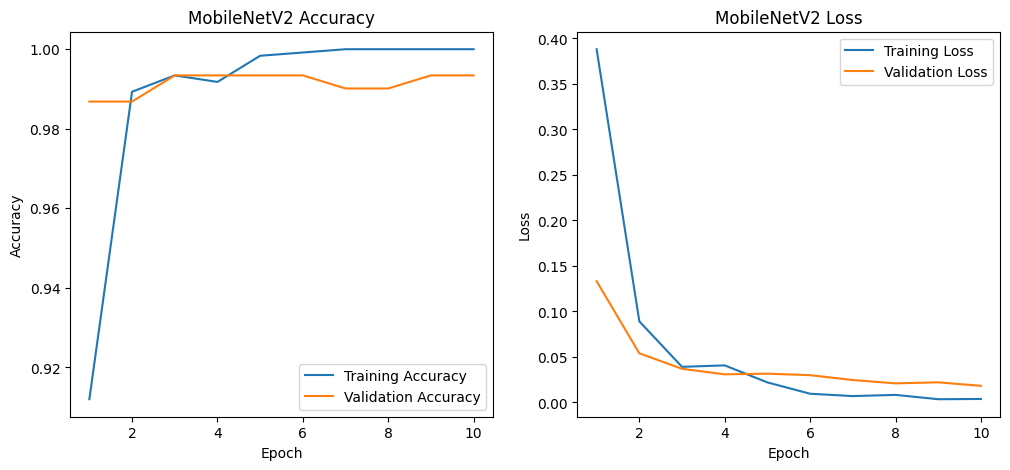

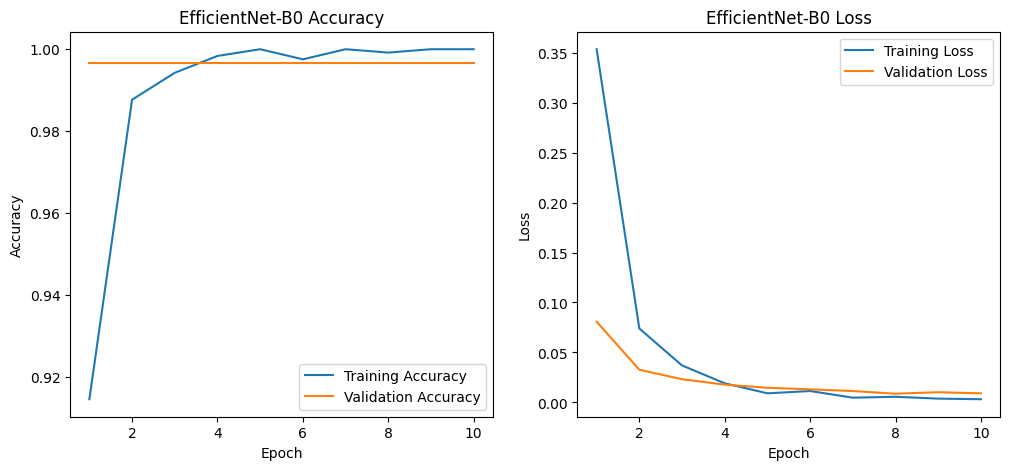

In [ ]:
import matplotlib.pyplot as plt

def plot_training_history(history, model_name):

    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)

    plt.plot(epochs, history["train_acc"], label="Training Accuracy")
    plt.plot(epochs, history["val_acc"], label="Validation Accuracy")

    plt.title(f"{model_name} Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.legend()

    plt.subplot(1, 2, 2)

    plt.plot(epochs, history["train_loss"], label="Training Loss")
    plt.plot(epochs, history["val_loss"], label="Validation Loss")

    plt.title(f"{model_name} Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.legend()

    plt.show()


plot_training_history(mobilenet_history, "MobileNetV2")

plot_training_history(efficientnet_history, "EfficientNet-B0")

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    f1_score,
    ConfusionMatrixDisplay
)

def evaluate_model(model, data_loader, model_name):

    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predicted.cpu().numpy())

    f1 = f1_score(all_labels, all_predictions)

    print(f"{model_name} F1 Score: {f1:.4f}")

    print("\nClassification Report")
    print(classification_report(
        all_labels,
        all_predictions,
        target_names=["Non-Fire", "Fire"]
    ))

    cm = confusion_matrix(all_labels, all_predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-Fire", "Fire"]
    )

    disp.plot(cmap="Oranges")

    plt.title(f"{model_name} Confusion Matrix")

    plt.show()

MobileNetV2 F1 Score: 0.9928

Classification Report
              precision    recall  f1-score   support

    Non-Fire       0.99      0.99      0.99       165
        Fire       0.99      0.99      0.99       139

    accuracy                           0.99       304
   macro avg       0.99      0.99      0.99       304
weighted avg       0.99      0.99      0.99       304



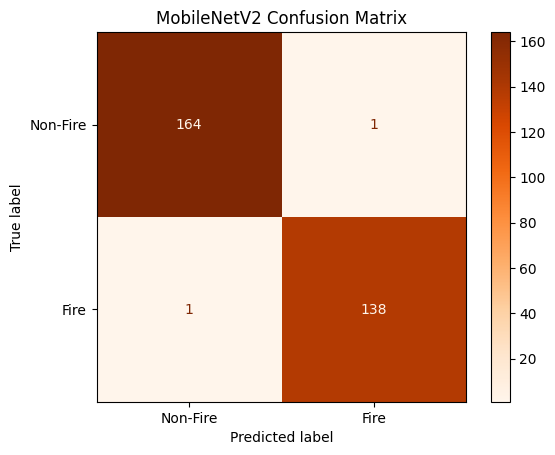

EfficientNet-B0 F1 Score: 0.9964

Classification Report
              precision    recall  f1-score   support

    Non-Fire       0.99      1.00      1.00       165
        Fire       1.00      0.99      1.00       139

    accuracy                           1.00       304
   macro avg       1.00      1.00      1.00       304
weighted avg       1.00      1.00      1.00       304



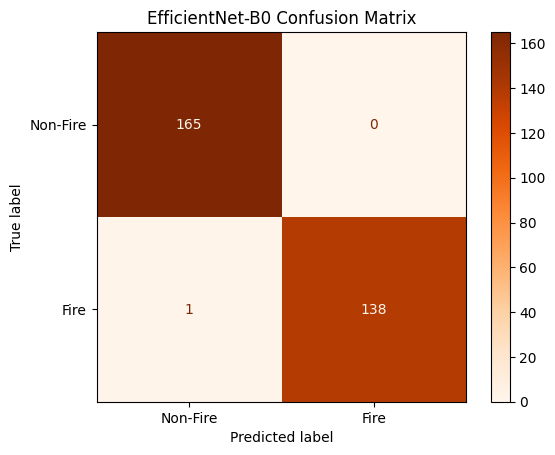

In [ ]:
evaluate_model(
    mobilenet_model,
    val_loader,
    "MobileNetV2"
)

evaluate_model(
    efficientnet_model,
    val_loader,
    "EfficientNet-B0"
)

The training and validation curves indicate that both transfer learning models learned the classification task effectively and converged within a relatively small number of training epochs. The close alignment between training and validation performance also suggests that overfitting was limited.

MobileNetV2 achieved an F1 score of 0.9928, while EfficientNet-B0 obtained the highest F1 score of 0.9964, demonstrating excellent classification performance across both classes.

The confusion matrices further confirm the effectiveness of the models, with only a small number of misclassified samples. Among the evaluated architectures, EfficientNet-B0 achieved the strongest overall performance, producing only a single incorrect prediction on the validation dataset.

Overall, the results demonstrate that transfer learning substantially improves classification performance compared with the baseline CNN model. Furthermore, the strong performance achieved by MobileNetV2 and EfficientNet-B0 highlights their potential for deployment in real-time edge AI wildfire detection systems.


# 8. Edge AI Optimisation

This section focuses on optimising the trained models for deployment in edge AI environments, where computational resources, memory capacity, and energy consumption are often limited.

Dynamic quantisation is applied to reduce model size and improve CPU inference efficiency while preserving classification performance as much as possible. The original and quantised models are then compared in terms of accuracy, inference latency, model size, and estimated memory usage.

These deployment-related metrics are critical when evaluating the practicality of running deep learning models on resource-constrained devices such as drones, IoT sensors, embedded systems, and intelligent surveillance platforms.

The objective of this stage is to determine whether model optimisation can improve deployment efficiency while maintaining acceptable predictive performance for real-time forest fire detection applications.


### Target Edge Device Scenario

The proposed deployment scenario is a smart surveillance camera or Raspberry Pi 5-based edge device placed in forest monitoring areas. The device captures images locally and runs the fire/no-fire classification model without sending every image to the cloud.

In this project, the target edge device is assumed to have limited CPU, memory, and energy resources. Therefore, model size, CPU inference latency, estimated memory usage, and bandwidth reduction are evaluated as key deployment metrics.

The selected edge deployment candidate is the quantised MobileNetV2 model because it provides high validation accuracy with lower latency and smaller memory requirements compared with EfficientNet-B0.

In [ ]:
import copy
import time
import os
import tempfile
import pandas as pd
import torch.quantization

In [ ]:
def get_model_size_mb(model):

    with tempfile.NamedTemporaryFile(delete=False) as temp_file:

        torch.save(model.state_dict(), temp_file.name)

        size_mb = os.path.getsize(temp_file.name) / (1024 * 1024)

    os.remove(temp_file.name)

    return size_mb


def estimate_model_memory_mb(model):

    total_memory = 0

    for param in model.parameters():

        total_memory += param.nelement() * param.element_size()

    for buffer in model.buffers():

        total_memory += buffer.nelement() * buffer.element_size()

    return total_memory / (1024 * 1024)

In [ ]:
def evaluate_model_accuracy_cpu(model, data_loader):

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.cpu()
            labels = labels.cpu()

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    return correct / total


def measure_cpu_latency(model, data_loader, num_batches=20):

    model.eval()

    latencies = []

    with torch.no_grad():

        for batch_idx, (images, labels) in enumerate(data_loader):

            if batch_idx >= num_batches:
                break

            images = images.cpu()

            start_time = time.time()

            _ = model(images)

            end_time = time.time()

            batch_latency = (end_time - start_time) * 1000

            single_image_latency = batch_latency / images.size(0)

            latencies.append(single_image_latency)

    return sum(latencies) / len(latencies)

In [ ]:
mobilenet_original_cpu = copy.deepcopy(mobilenet_model).cpu()

efficientnet_original_cpu = copy.deepcopy(efficientnet_model).cpu()

mobilenet_original_cpu.eval()

efficientnet_original_cpu.eval()

print("Original CPU models are ready.")

Original CPU models are ready.


In [ ]:
mobilenet_quantized = torch.quantization.quantize_dynamic(
    mobilenet_original_cpu,
    {nn.Linear},
    dtype=torch.qint8
)

efficientnet_quantized = torch.quantization.quantize_dynamic(
    efficientnet_original_cpu,
    {nn.Linear},
    dtype=torch.qint8
)

mobilenet_quantized.eval()

efficientnet_quantized.eval()

print("Dynamic quantisation completed.")

Dynamic quantisation completed.


In [ ]:
edge_results = []

models_to_compare = [
    ("MobileNetV2 Original", mobilenet_original_cpu),
    ("MobileNetV2 Quantized", mobilenet_quantized),
    ("EfficientNet-B0 Original", efficientnet_original_cpu),
    ("EfficientNet-B0 Quantized", efficientnet_quantized)
]

for model_name, model in models_to_compare:

    accuracy = evaluate_model_accuracy_cpu(
        model,
        val_loader
    )

    size_mb = get_model_size_mb(model)

    latency_ms = measure_cpu_latency(
        model,
        val_loader
    )

    memory_mb = estimate_model_memory_mb(model)

    edge_results.append({
        "Model": model_name,
        "Validation Accuracy": accuracy,
        "Model Size (MB)": size_mb,
        "CPU Latency per Image (ms)": latency_ms,
        "Estimated Memory (MB)": memory_mb
    })

edge_results_df = pd.DataFrame(edge_results)

edge_results_df

,Model,Validation Accuracy,Model Size (MB),CPU Latency per Image (ms),Estimated Memory (MB)
0,MobileNetV2 Original,0.993421,8.723521,51.137991,8.623695
1,MobileNetV2 Quantized,0.993421,8.717055,49.534737,8.613922
2,EfficientNet-B0 Original,0.996711,15.578528,61.235768,15.458008
3,EfficientNet-B0 Quantized,0.996711,15.572001,64.235149,15.448235


In [ ]:
edge_results_summary = edge_results_df.copy()

edge_results_summary["Validation Accuracy"] = edge_results_summary["Validation Accuracy"].apply(
    lambda x: f"{x:.4f}"
)

edge_results_summary["Model Size (MB)"] = edge_results_summary["Model Size (MB)"].apply(
    lambda x: f"{x:.2f}"
)

edge_results_summary["CPU Latency per Image (ms)"] = edge_results_summary["CPU Latency per Image (ms)"].apply(
    lambda x: f"{x:.2f}"
)

edge_results_summary["Estimated Memory (MB)"] = edge_results_summary["Estimated Memory (MB)"].apply(
    lambda x: f"{x:.2f}"
)

edge_results_summary

,Model,Validation Accuracy,Model Size (MB),CPU Latency per Image (ms),Estimated Memory (MB)
0,MobileNetV2 Original,0.9934,8.72,51.14,8.62
1,MobileNetV2 Quantized,0.9934,8.72,49.53,8.61
2,EfficientNet-B0 Original,0.9967,15.58,61.24,15.46
3,EfficientNet-B0 Quantized,0.9967,15.57,64.24,15.45


# 9. Edge vs Cloud Simulation

This section compares two deployment scenarios for forest fire detection: edge inference and cloud-based inference.

In the edge scenario, images are processed directly on the local device, meaning that the total response time is primarily determined by the model's inference latency.

In the cloud scenario, images must first be transmitted to a remote server for processing. As a result, the total latency includes data upload time, network communication delays, and server-side inference time.

This comparison helps illustrate the potential advantages of edge AI for time-sensitive wildfire detection applications, particularly in remote or low-connectivity environments where reliable network access cannot always be guaranteed.

The cloud deployment scenario is simulated using assumed network conditions and upload delays rather than being evaluated on a real cloud infrastructure. Consequently, the results should be interpreted as an approximate comparison intended to demonstrate deployment trade-offs rather than exact real-world performance measurements.


In [ ]:
selected_edge_model = "MobileNetV2 Quantized"

edge_latency_ms = edge_results_df.loc[
    edge_results_df["Model"] == selected_edge_model,
    "CPU Latency per Image (ms)"
].values[0]

average_image_size_mb = 0.25
upload_speed_mbps = 5
network_delay_ms = 200
cloud_inference_latency_ms = 80

upload_speed_MBps = upload_speed_mbps / 8

upload_delay_ms = (average_image_size_mb / upload_speed_MBps) * 1000

cloud_total_latency_ms = (
    upload_delay_ms
    + network_delay_ms
    + cloud_inference_latency_ms
)

edge_total_latency_ms = edge_latency_ms

latency_comparison = pd.DataFrame({
    "Scenario": ["Edge Inference", "Cloud Inference"],
    "Upload Delay (ms)": [0, upload_delay_ms],
    "Network Delay (ms)": [0, network_delay_ms],
    "Inference Latency (ms)": [edge_latency_ms, cloud_inference_latency_ms],
    "Total Latency (ms)": [edge_total_latency_ms, cloud_total_latency_ms]
})

latency_comparison

,Scenario,Upload Delay (ms),Network Delay (ms),Inference Latency (ms),Total Latency (ms)
0,Edge Inference,0.0,0,49.534737,49.534737
1,Cloud Inference,400.0,200,80.000000,680.000000


In [ ]:
latency_comparison_summary = latency_comparison.copy()

for column in latency_comparison_summary.columns[1:]:
    latency_comparison_summary[column] = latency_comparison_summary[column].apply(
        lambda x: f"{x:.2f}"
    )

latency_comparison_summary

,Scenario,Upload Delay (ms),Network Delay (ms),Inference Latency (ms),Total Latency (ms)
0,Edge Inference,0.00,0.00,49.53,49.53
1,Cloud Inference,400.00,200.00,80.00,680.00


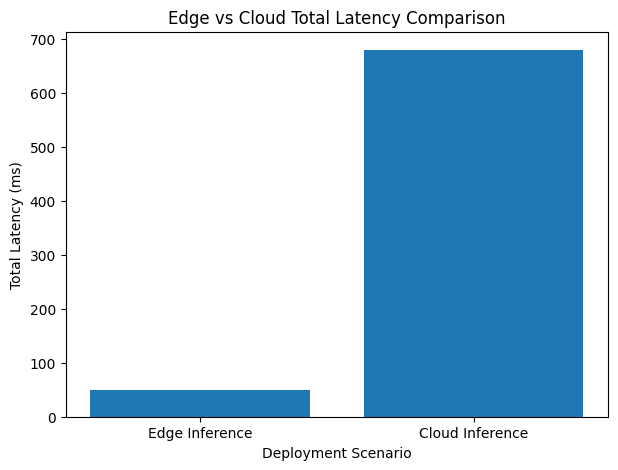

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    latency_comparison["Scenario"],
    latency_comparison["Total Latency (ms)"]
)

plt.title("Edge vs Cloud Total Latency Comparison")
plt.xlabel("Deployment Scenario")
plt.ylabel("Total Latency (ms)")

plt.show()

# 10. Bandwidth Analysis

This section examines the bandwidth implications of cloud-based image processing compared with edge AI deployment.

In a cloud-based system, images must be continuously transmitted to a remote server for inference. As the number of monitored images increases, network traffic, communication costs, and dependency on stable internet connectivity also increase. These factors can become significant challenges in large-scale or remote monitoring applications.

In contrast, edge AI performs inference directly on the local device, allowing decisions to be made without transmitting every image to the cloud. As a result, bandwidth consumption is substantially reduced, and the system becomes less dependent on network availability.

This analysis highlights one of the key advantages of edge AI for real-time forest fire monitoring systems, where efficient use of network resources and rapid decision-making are critical operational requirements.


In [ ]:
average_image_size_mb = 0.25

images_per_minute = 12

images_per_hour = images_per_minute * 60
images_per_day = images_per_hour * 24

hourly_transfer_mb = images_per_hour * average_image_size_mb
daily_transfer_mb = images_per_day * average_image_size_mb

daily_transfer_gb = daily_transfer_mb / 1024

edge_reduction_factor = 0.05

edge_hourly_transfer_mb = hourly_transfer_mb * edge_reduction_factor
edge_daily_transfer_mb = daily_transfer_mb * edge_reduction_factor

edge_daily_transfer_gb = edge_daily_transfer_mb / 1024

bandwidth_results = pd.DataFrame({
    "Scenario": ["Cloud-Based Monitoring", "Edge AI Monitoring"],
    "Hourly Transfer (MB)": [
        hourly_transfer_mb,
        edge_hourly_transfer_mb
    ],
    "Daily Transfer (MB)": [
        daily_transfer_mb,
        edge_daily_transfer_mb
    ],
    "Daily Transfer (GB)": [
        daily_transfer_gb,
        edge_daily_transfer_gb
    ]
})

bandwidth_results

,Scenario,Hourly Transfer (MB),Daily Transfer (MB),Daily Transfer (GB)
0,Cloud-Based Monitoring,180.0,4320.0,4.218750
1,Edge AI Monitoring,9.0,216.0,0.210938


In [ ]:
bandwidth_summary = bandwidth_results.copy()

for column in bandwidth_summary.columns[1:]:
    bandwidth_summary[column] = bandwidth_summary[column].apply(
        lambda x: f"{x:.2f}"
    )

bandwidth_summary

,Scenario,Hourly Transfer (MB),Daily Transfer (MB),Daily Transfer (GB)
0,Cloud-Based Monitoring,180.00,4320.00,4.22
1,Edge AI Monitoring,9.00,216.00,0.21


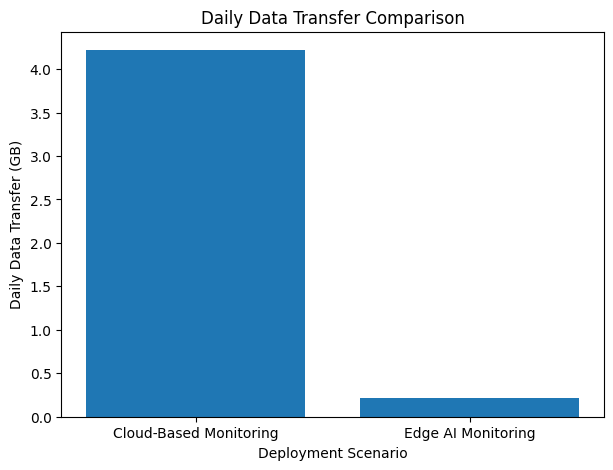

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    bandwidth_results["Scenario"],
    bandwidth_results["Daily Transfer (GB)"]
)

plt.title("Daily Data Transfer Comparison")
plt.xlabel("Deployment Scenario")
plt.ylabel("Daily Data Transfer (GB)")

plt.show()

# 11. Energy Efficiency Discussion

This section discusses the potential energy efficiency benefits of deploying wildfire detection models on edge devices.

Direct hardware power measurements were not conducted as part of this project. Instead, energy-related considerations are analysed indirectly through deployment characteristics such as reduced data transmission, lower dependence on cloud infrastructure, and faster local inference.

In cloud-based systems, continuous image transmission and remote processing can contribute to higher energy consumption, particularly when large volumes of data are exchanged over wireless networks. In contrast, edge AI enables data processing to occur locally, reducing communication overhead and potentially lowering overall system energy requirements.

These considerations are particularly relevant for remote monitoring applications that rely on battery-powered devices, solar-powered systems, drones, or embedded edge platforms. Therefore, energy efficiency is discussed from a system-level perspective rather than through direct hardware power measurements.


In [ ]:
energy_per_gb_cloud_kwh = 0.06

cloud_daily_gb = daily_transfer_gb
edge_daily_gb = edge_daily_transfer_gb

cloud_energy_kwh = cloud_daily_gb * energy_per_gb_cloud_kwh
edge_energy_kwh = edge_daily_gb * energy_per_gb_cloud_kwh

energy_results = pd.DataFrame({
    "Scenario": ["Cloud-Based Monitoring", "Edge AI Monitoring"],
    "Daily Data Transfer (GB)": [
        cloud_daily_gb,
        edge_daily_gb
    ],
    "Estimated Daily Transmission Energy (kWh)": [
        cloud_energy_kwh,
        edge_energy_kwh
    ]
})

energy_results

,Scenario,Daily Data Transfer (GB),Estimated Daily Transmission Energy (kWh)
0,Cloud-Based Monitoring,4.218750,0.253125
1,Edge AI Monitoring,0.210938,0.012656


In [ ]:
energy_summary = energy_results.copy()

energy_summary["Daily Data Transfer (GB)"] = energy_summary[
    "Daily Data Transfer (GB)"
].apply(lambda x: f"{x:.2f}")

energy_summary["Estimated Daily Transmission Energy (kWh)"] = energy_summary[
    "Estimated Daily Transmission Energy (kWh)"
].apply(lambda x: f"{x:.4f}")

energy_summary

,Scenario,Daily Data Transfer (GB),Estimated Daily Transmission Energy (kWh)
0,Cloud-Based Monitoring,4.22,0.2531
1,Edge AI Monitoring,0.21,0.0127


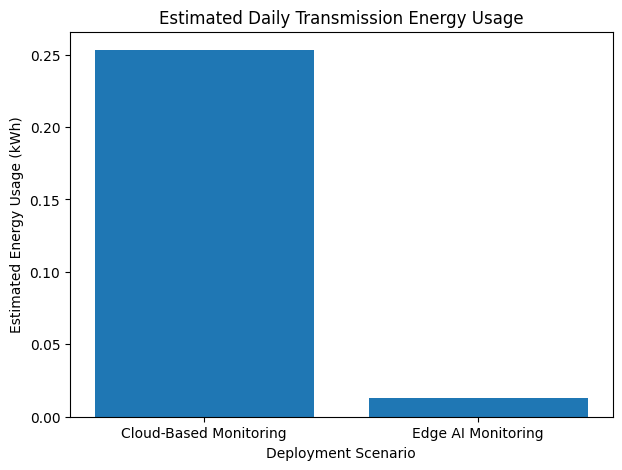

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    energy_results["Scenario"],
    energy_results["Estimated Daily Transmission Energy (kWh)"]
)

plt.title("Estimated Daily Transmission Energy Usage")
plt.xlabel("Deployment Scenario")
plt.ylabel("Estimated Energy Usage (kWh)")

plt.show()

# 12. Final Inference Demo

This section demonstrates the final wildfire detection system through a single-image inference example.

A test image is loaded, preprocessed using the same pipeline applied during model training, and passed through the trained model to generate a prediction together with a confidence score. This process illustrates how the model can classify previously unseen images in a deployment scenario.

The demonstration represents the complete inference workflow, from image input to prediction output, and provides a practical example of how the system could operate on an edge device for real-time wildfire monitoring.

By performing inference on individual images, this final stage showcases the operational capability of the developed model and highlights its potential use in real-world edge AI applications.


In [ ]:
from PIL import Image
import torch.nn.functional as F

In [ ]:
class_names = ["Fire", "Non-Fire"]

final_model = efficientnet_model
final_model.eval()

def predict_single_image(image_path, model, transform):

    image = Image.open(image_path).convert("RGB")

    input_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():

        outputs = model(input_tensor)

        probabilities = F.softmax(outputs, dim=1)

        confidence, predicted_class = torch.max(probabilities, 1)

    prediction = class_names[predicted_class.item()]
    confidence_score = confidence.item() * 100

    plt.figure(figsize=(6, 6))

    plt.imshow(image)

    plt.title(
        f"Prediction: {prediction}\nConfidence: {confidence_score:.2f}%"
    )

    plt.axis("off")

    plt.show()

    print(f"Prediction: {prediction}")
    print(f"Confidence Score: {confidence_score:.2f}%")

In [ ]:
import random
import os

test_image_paths = []

for root, dirs, files in os.walk(test_dir):

    for file in files:

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            test_image_paths.append(
                os.path.join(root, file)
            )

random_test_image = random.choice(test_image_paths)

print("Selected Test Image:")
print(random_test_image)

Selected Test Image:
/content/forest_fire_project/dataset/Forest Fire Dataset/Testing/nofire_0332.jpg


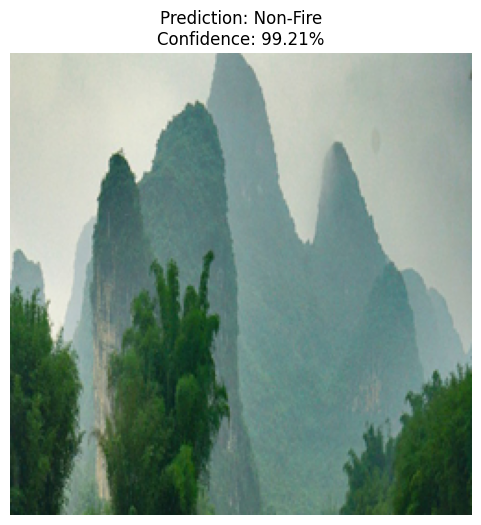

Prediction: Non-Fire
Confidence Score: 99.21%


In [ ]:
predict_single_image(
    random_test_image,
    final_model,
    eval_transforms
)

# 13. Final Comparison Tables

This section summaris# 14. Final Comparison Tables

This section summarises the key findings obtained throughout the project and provides a consolidated comparison of the evaluated models.

The final comparison tables bring together the most important deployment and performance metrics, including classification accuracy, model size, CPU inference latency, and estimated memory usage. By examining these metrics together, it is possible to evaluate the trade-offs between predictive performance and deployment efficiency.

The results support the selection of the most appropriate model for real-world edge AI wildfire detection applications, taking into account both classification effectiveness and resource constraints. This comparison also highlights the benefits of using efficient deep learning architectures for deployment on resource-limited edge devices.
es the main experimental results of the project.

The final comparison tables bring together model accuracy, model size, CPU inference latency and estimated memory usage. These results help identify the most suitable model for edge AI wildfire detection deployment.

In [ ]:
final_model_results = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "MobileNetV2",
        "EfficientNet-B0"
    ],
    "Validation Accuracy": [
        baseline_final_val_acc,
        mobilenet_final_val_acc,
        efficientnet_final_val_acc
    ]
})

final_model_results

,Model,Validation Accuracy
0,Baseline CNN,0.960526
1,MobileNetV2,0.993421
2,EfficientNet-B0,0.996711


In [ ]:
final_model_results_summary = final_model_results.copy()

final_model_results_summary["Validation Accuracy"] = final_model_results_summary[
    "Validation Accuracy"
].apply(lambda x: f"{x:.4f}")

final_model_results_summary

,Model,Validation Accuracy
0,Baseline CNN,0.9605
1,MobileNetV2,0.9934
2,EfficientNet-B0,0.9967


In [ ]:
final_edge_comparison = edge_results_df.copy()

final_edge_comparison

,Model,Validation Accuracy,Model Size (MB),CPU Latency per Image (ms),Estimated Memory (MB)
0,MobileNetV2 Original,0.993421,8.723521,51.137991,8.623695
1,MobileNetV2 Quantized,0.993421,8.717055,49.534737,8.613922
2,EfficientNet-B0 Original,0.996711,15.578528,61.235768,15.458008
3,EfficientNet-B0 Quantized,0.996711,15.572001,64.235149,15.448235


In [ ]:
best_edge_model = final_edge_comparison.sort_values(
    by=["CPU Latency per Image (ms)", "Model Size (MB)"],
    ascending=[True, True]
).iloc[0]

print("Best Edge Deployment Candidate")
print("-" * 40)
print(f"Model: {best_edge_model['Model']}")
print(f"Validation Accuracy: {best_edge_model['Validation Accuracy']:.4f}")
print(f"Model Size: {best_edge_model['Model Size (MB)']:.2f} MB")
print(f"CPU Latency per Image: {best_edge_model['CPU Latency per Image (ms)']:.2f} ms")
print(f"Estimated Memory: {best_edge_model['Estimated Memory (MB)']:.2f} MB")

Best Edge Deployment Candidate
----------------------------------------
Model: MobileNetV2 Quantized
Validation Accuracy: 0.9934
Model Size: 8.72 MB
CPU Latency per Image: 49.53 ms
Estimated Memory: 8.61 MB


## 14. Conclusion

This project investigated the use of deep learning and Edge AI techniques for real-time forest fire detection. A baseline CNN model was first developed and then compared with two transfer learning architectures, MobileNetV2 and EfficientNet-B0.

The experimental results demonstrated that transfer learning significantly improved classification performance. Among the evaluated models, EfficientNet-B0 achieved the highest validation accuracy and F1 score, while MobileNetV2 also delivered excellent performance with a lightweight architecture suitable for edge deployment.

Further analysis showed that model optimisation techniques such as quantisation can reduce deployment costs while maintaining strong predictive performance. The edge-versus-cloud comparison highlighted the benefits of local inference, including reduced latency, lower bandwidth requirements, and improved suitability for remote monitoring environments.

Overall, the findings suggest that Edge AI provides a practical and efficient approach for real-time wildfire detection. The developed system demonstrates how modern deep learning models can be adapted for deployment on resource-constrained edge devices while maintaining high classification accuracy.
